# Reproducing Figure 6: the two-particle triangle functional

This notebook reproduces the geometry and analytic functional in Figure 6 of Penz and van Leeuwen, *Density-functional theory on graphs* (2021), Eq. (96), p. 18. The domain is

\[
\mathcal P_{3,2}=\{\rho\in[0,1]^3:\rho_1+\rho_2+\rho_3=2\}.
\]

The central disk `C` is a flat region where `F = 3`. To avoid unnecessary computation, the evaluator returns 3 directly for points inside the disk and skips the square roots in the three branches. The plot omits the flat region and shows only its boundary. Outside the disk, it evaluates the three closed-form branches from Eq. (96).

The domain is parameterized as an equilateral triangle with side length 1. The vertical surface shows \(\tilde F(\rho)\). The disk is centered at \( (2/3,2/3,2/3)\), and its boundary in density coordinates satisfies

\[
\sum_{i=1}^3(\rho_i-2/3)^2=1/6.
\]

The three points of tangency on the triangle boundary are the exceptional densities obtained by permuting \( (1,1/2,1/2)\).


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm

# Plot reference: an equilateral triangle with side length 1.
SQRT3 = np.sqrt(3.0)
VERTICES = np.array([
    [0.0, 0.0],              # h1 = 1, rho = (0, 1, 1)
    [1.0, 0.0],              # h2 = 1, rho = (1, 0, 1)
    [0.5, SQRT3 / 2.0],       # h3 = 1, rho = (1, 1, 0)
])
TRIANGLE_CENTER = VERTICES.mean(axis=0)
INCIRCLE_RADIUS = SQRT3 / 6.0


def rho_to_xy(rho):
    """Convert densities (..., 3) to equilateral-triangle coordinates (..., 2)."""
    rho = np.asarray(rho, dtype=float)
    if rho.shape[-1] != 3:
        raise ValueError("The last dimension of rho must have length 3.")
    holes = 1.0 - rho
    return holes @ VERTICES


def xy_to_rho(x, y):
    """Convert equilateral-triangle coordinates to densities (..., 3)."""
    x, y = np.broadcast_arrays(np.asarray(x, dtype=float), np.asarray(y, dtype=float))
    h3 = 2.0 * y / SQRT3
    h2 = x - 0.5 * h3
    h1 = 1.0 - h2 - h3
    holes = np.stack((h1, h2, h3), axis=-1)
    return 1.0 - holes


def _inside_density_domain(rho, tol=1e-10):
    return (
        np.all((rho >= -tol) & (rho <= 1.0 + tol), axis=-1)
        & (np.abs(np.sum(rho, axis=-1) - 2.0) <= tol)
    )


def functional_and_region(rho, tol=1e-12):
    """Vectorized exact F-tilde for one density or a batch shaped (..., 3).

    Points in the central disk return 3 immediately. Outside it, Eq. (96)'s
    three candidate branches are evaluated and the minimum branch is selected.
    Invalid points outside P_(3,2) return NaN and region='outside'.
    """
    rho = np.asarray(rho, dtype=float)
    if rho.shape[-1] != 3:
        raise ValueError("The last dimension of rho must have length 3.")

    original_shape = rho.shape[:-1]
    flat = rho.reshape(-1, 3)
    valid = _inside_density_domain(flat)
    # In ambient density coordinates the incircle has squared radius 1/6.
    dist2 = np.sum((flat - (2.0 / 3.0)) ** 2, axis=1)
    central = valid & (dist2 <= (1.0 / 6.0 + tol))

    values = np.full(len(flat), np.nan, dtype=float)
    region = np.full(len(flat), "outside", dtype=object)
    values[central] = 3.0
    region[central] = "C"

    outer = valid & ~central
    if np.any(outer):
        r = np.clip(flat[outer], 0.0, 1.0)
        r1, r2, r3 = r.T
        # The three square-root factors used in Eq. (96).
        a1 = np.sqrt((1.0 - r1) * (1.0 - r3))
        a2 = np.sqrt((1.0 - r1) * (1.0 - r2))
        a3 = np.sqrt((1.0 - r2) * (1.0 - r3))
        branches = np.stack((
            a1 - a2 - a3,  # S1
            -a1 - a2 + a3, # S2
            -a1 + a2 - a3, # S3
        ), axis=-1)
        active = np.argmin(branches, axis=-1)
        values[outer] = 4.0 + 2.0 * branches[np.arange(np.sum(outer)), active]
        region[outer] = np.array(["S1", "S2", "S3"], dtype=object)[active]

    return values.reshape(original_shape), region.reshape(original_shape)


def functional(rho, tol=1e-12):
    """Fast value-only evaluator for repeated pointwise calculations."""
    rho = np.asarray(rho, dtype=float)
    if rho.shape[-1] != 3:
        raise ValueError("The last dimension of rho must have length 3.")

    original_shape = rho.shape[:-1]
    flat = rho.reshape(-1, 3)
    valid = _inside_density_domain(flat)
    dist2 = np.sum((flat - (2.0 / 3.0)) ** 2, axis=1)
    central = valid & (dist2 <= (1.0 / 6.0 + tol))

    values = np.full(len(flat), np.nan, dtype=float)
    values[central] = 3.0
    outer = valid & ~central
    if np.any(outer):
        r1, r2, r3 = np.clip(flat[outer], 0.0, 1.0).T
        a1 = np.sqrt((1.0 - r1) * (1.0 - r3))
        a2 = np.sqrt((1.0 - r1) * (1.0 - r2))
        a3 = np.sqrt((1.0 - r2) * (1.0 - r3))
        branches = np.stack((
            a1 - a2 - a3,
            -a1 - a2 + a3,
            -a1 + a2 - a3,
        ), axis=-1)
        values[outer] = 4.0 + 2.0 * np.min(branches, axis=-1)

    return values.reshape(original_shape)


## Checks at notable points

The center and the three points of tangency have value 3; the three triangle vertices have value 4. An additional point outside the disk is checked against its analytic branch. These checks do not optimize over phases: use the closed-form expression for repeated pointwise evaluations.


In [5]:
rho_center = np.array([2/3, 2/3, 2/3])
tangent_points = np.array([
    [1.0, 0.5, 0.5],
    [0.5, 1.0, 0.5],
    [0.5, 0.5, 1.0],
])
vertices_rho = np.array([
    [0.0, 1.0, 1.0],
    [1.0, 0.0, 1.0],
    [1.0, 1.0, 0.0],
])

assert np.isclose(functional(rho_center), 3.0)
assert np.allclose(functional(tangent_points), 3.0, atol=1e-10)
assert np.allclose(functional(vertices_rho), 4.0, atol=1e-10)
assert np.allclose(rho_to_xy(xy_to_rho(*TRIANGLE_CENTER)), TRIANGLE_CENTER)

check_rho = np.array([0.133, 0.9335, 0.9335])
check_value, check_region = functional_and_region(check_rho)
print("F(center) =", float(functional(rho_center)))
print("F(tangencies) =", functional(tangent_points))
print("F(vertices) =", functional(vertices_rho))
print(f"F({check_rho}) = {float(check_value):.12f} in {check_region}")


F(center) = 3.0
F(tangencies) = [3. 3. 3.]
F(vertices) = [4. 4. 4.]
F([0.133  0.9335 0.9335]) = 3.172537611356 in S2


## Outer surface and disk boundary

The grid covers the full triangle, but the plot omits the surface over the central disk: its value is known exactly to be 3, and the boundary identifies the region. Grid values are evaluated in a vectorized operation.


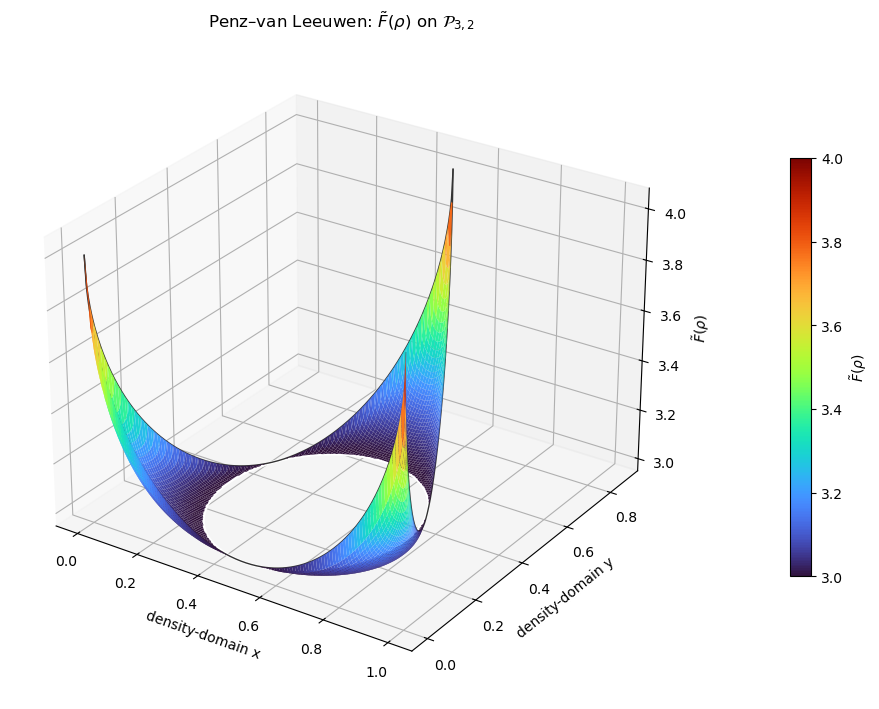

In [8]:
n_grid = 240
x_values = np.linspace(0.0, 1.0, n_grid)
y_values = np.linspace(0.0, SQRT3 / 2.0, n_grid)
X, Y = np.meshgrid(x_values, y_values)
RHO = xy_to_rho(X, Y)

# Mask the rectangular area outside the equilateral triangle.
holes_grid = 1.0 - RHO
in_triangle = np.all(holes_grid >= -1e-10, axis=-1)
Z = functional(RHO)

# Omit the flat region C and draw only its boundary at F = 3.
distance2 = np.sum((RHO - 2.0/3.0)**2, axis=-1)
in_central_disk = distance2 <= (1.0/6.0 + 1e-12)
Z_plot = np.where(in_triangle & ~in_central_disk, Z, np.nan)

fig = plt.figure(figsize=(10, 7.2))
ax = fig.add_subplot(111, projection="3d")
surface = ax.plot_surface(
    X, Y, Z_plot,
    cmap="turbo",
    linewidth=0,
    antialiased=True,
    rcount=180,
    ccount=180,
    vmin=3.0,
    vmax=4.0,
)

# Draw the central circle boundary without computing or plotting the disk interior.
theta = np.linspace(0.0, 2.0*np.pi, 500)
circle_x = TRIANGLE_CENTER[0] + INCIRCLE_RADIUS*np.cos(theta)
circle_y = TRIANGLE_CENTER[1] + INCIRCLE_RADIUS*np.sin(theta)
ax.plot(circle_x, circle_y, np.full_like(theta, 3.0), color="white", linewidth=2.2)

# Draw the domain boundary with heights from the analytic formula.
for i in range(3):
    p0, p1 = VERTICES[i], VERTICES[(i+1) % 3]
    t = np.linspace(0.0, 1.0, 300)
    edge_xy = (1-t[:, None])*p0 + t[:, None]*p1
    edge_rho = xy_to_rho(edge_xy[:, 0], edge_xy[:, 1])
    ax.plot(edge_xy[:, 0], edge_xy[:, 1], functional(edge_rho), color="0.2", linewidth=1.0)

ax.set_xlabel("density-domain x")
ax.set_ylabel("density-domain y")
ax.set_zlabel(r"$\tilde F(\rho)$")
ax.set_title(r"Penz–van Leeuwen: $\tilde F(\rho)$ on $\mathcal{P}_{3,2}$")
ax.set_zlim(2.95, 4.08)
ax.view_init(elev=27, azim=-56)
fig.colorbar(surface, ax=ax, shrink=0.63, pad=0.12, label=r"$\tilde F(\rho)$")
plt.tight_layout()
plt.show()


## 2D domain and boundary

This view shows the density triangle, central disk, and three outer sectors. The circular boundary uses its exact geometric parameterization, so no interior grid is needed.


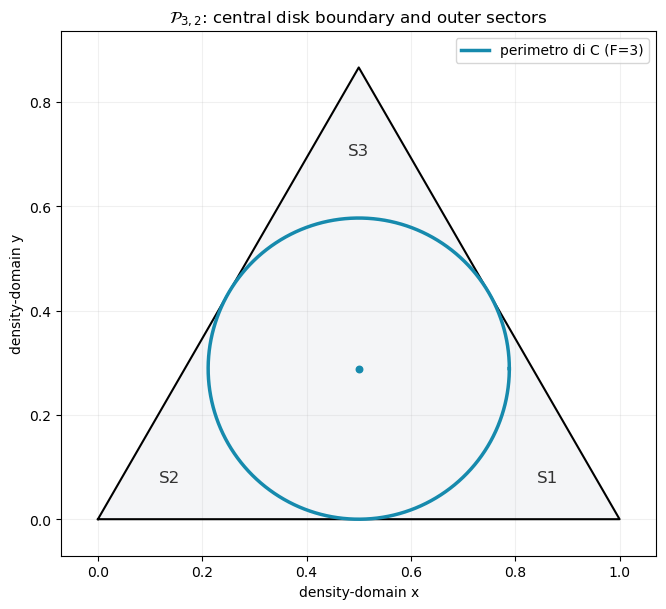

In [11]:
fig2, ax2 = plt.subplots(figsize=(7.0, 6.2))
triangle_closed = np.vstack((VERTICES, VERTICES[0]))
ax2.plot(triangle_closed[:, 0], triangle_closed[:, 1], color="black", linewidth=1.5)
ax2.fill(VERTICES[:, 0], VERTICES[:, 1], color="#f4f5f7", zorder=0)
ax2.plot(circle_x, circle_y, color="#168aad", linewidth=2.5, label="perimetro di C (F=3)")
ax2.scatter(*TRIANGLE_CENTER, color="#168aad", s=22, zorder=3)

# Branch labels in the three outer sectors (Eq. 96).
sector_vertex = {"S2": VERTICES[0], "S1": VERTICES[1], "S3": VERTICES[2]}
for label, vertex in sector_vertex.items():
    direction = vertex - TRIANGLE_CENTER
    label_xy = TRIANGLE_CENTER + 1.45*INCIRCLE_RADIUS*direction/np.linalg.norm(direction)
    ax2.text(*label_xy, label, ha="center", va="center", fontsize=12, color="#333333")

ax2.set_aspect("equal")
ax2.set_xlim(-0.07, 1.07)
ax2.set_ylim(-0.07, SQRT3/2.0 + 0.07)
ax2.set_xlabel("density-domain x")
ax2.set_ylabel("density-domain y")
ax2.set_title(r"$\mathcal{P}_{3,2}$: central disk boundary and outer sectors")
ax2.legend(loc="upper right")
ax2.grid(alpha=0.18)
plt.tight_layout()
plt.show()


## Pointwise evaluation for repeated experiments

`functional(rho_batch)` accepts an array with shape `(n_samples, 3)` and returns all values in one call. Points in the central region receive the exact value 3; the square-root branches are evaluated only for samples outside it. If the samples have already been classified, `functional_and_region` also returns their region labels: `C`, `S1`, `S2`, or `S3`.

For repeated sampling, keep the existing `rho_batch` array and call the function only for new samples. There is no need to optimize over phases for each point.


In [14]:
# Batch interface example (replace with samples from an experiment).
rho_batch = np.array([
    [2/3, 2/3, 2/3],
    [0.133, 0.9335, 0.9335],
    [0.5, 0.5, 1.0],
])
F_batch, region_batch = functional_and_region(rho_batch)
print(np.column_stack((rho_batch, F_batch, region_batch)))


[[0.6666666666666666 0.6666666666666666 0.6666666666666666 3.0 'C']
 [0.133 0.9335 0.9335 3.172537611355864 'S2']
 [0.5 0.5 1.0 3.0 'C']]
